<a href="https://colab.research.google.com/github/Kaihan7/Python-ML-ES/blob/main/L/L_1/l_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Dependencies

In [3]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import math
import pickle

# Generate Data

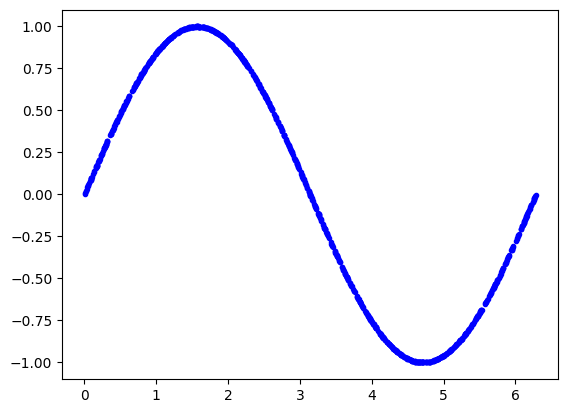

In [8]:
# We'll generate this many datapoints
SAMPLES = 1000

# Set a 'seed' variable, to get the same random numbers each time the code is executed
SEED = 1337
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Generate a uniformly distributed set of random numbers in the range from 0 to 2π
x_values = np.random.uniform(low=0, high=2*math.pi, size=SAMPLES)

# Shuffle the values to guarantee they're not in order
np.random.shuffle(x_values)

# Calculate the corresponding sine values
y_values = np.sin(x_values)

# Plot our data. The 'b.' argument tells the library to print blue dots.
plt.plot(x_values, y_values, 'b.')
plt.show()

# Add Noise

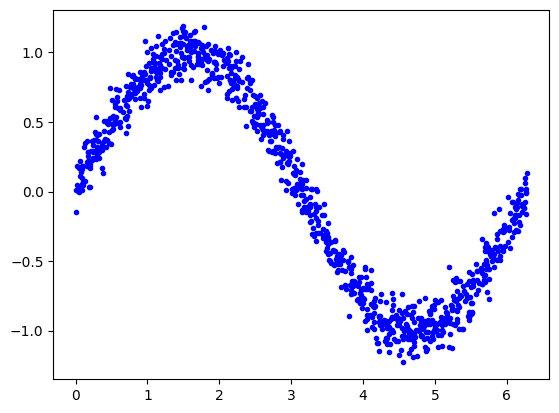

In [9]:
# Add a small random number to each y value
y_values += 0.1 * np.random.randn(*y_values.shape)

# Plot the data
plt.plot(x_values, y_values, 'b.')
plt.show()

# Make Data Ready For Training

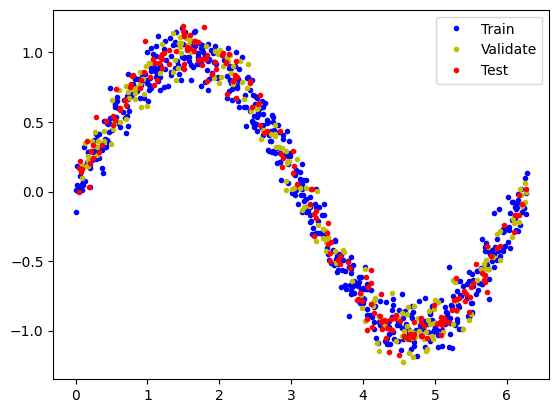

In [10]:
# We'll split the data into [Training, Testing, Validation] = [60%, 20%, 20%]
TRAIN_SPLIT = int(0.6 * SAMPLES)
TEST_SPLIT = int(0.2*SAMPLES+TRAIN_SPLIT)

# Use np.split to chop up our data into three parts.
# The second argument of np.split is an array of indices where the data will be split.
# We provide two indices, so the data will be divided into three chunks.
x_train, x_validate, x_test = np.split(x_values, [TRAIN_SPLIT, TEST_SPLIT])
y_train, y_validate, y_test = np.split(y_values, [TRAIN_SPLIT, TEST_SPLIT])

# Assert that the data was split correctly
assert (x_train.size + x_validate.size + x_test.size) == SAMPLES

# Plot the data from each partition in different colors
plt.plot(x_train, y_train, 'b.', label="Train")
plt.plot(x_validate, y_validate, 'y.', label="Validate")
plt.plot(x_test, y_test, 'r.', label="Test")
plt.legend()
plt.show()

# Save data for future use

In [7]:

data = {
    "x_train":x_train,
    "y_train":y_train,
    "x_test":x_test,
    "y_test":y_test,
    "x_validate":x_validate,
    "y_validate":y_validate,
}

with open('data.pkl', 'wb') as outp:
    pickle.dump(data, outp, pickle.HIGHEST_PROTOCOL)
